# Przetwarzanie języka naturalnego (NLP) i modele generatywne

## Lab 2 – Klasyfikacja tekstu

Prowadzący: mgr inż. M. Krzywda

Autor: Sebastian Kowalski

Repozytorium projektu: https://github.com/sebastiankowalski2/NLP_BOT

## 1. Konfiguracja i importy

W drugiej części projektu rozszerzono bota TODO o klasyfikację tekstu. Wykorzystano bibliotekę `scikit-learn` do przygotowania reprezentacji tekstu i trenowania klasyfikatorów oraz `spaCy` do uzyskania wektorów dokumentów.

Notebook korzysta z modułów projektu (`classification_data.py` i `classification.py`), dzięki czemu prezentowany kod odpowiada implementacji wykorzystanej przez bota Discord.

In [1]:
%pip install -q scikit-learn pandas numpy matplotlib seaborn spacy joblib
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import classification_data as cdata
import classification as clf

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 30)


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Dane do klasyfikacji

Do eksperymentów wykorzystano zbiór **20 Newsgroups**. Zastosowano cztery kategorie tematyczne:

- `comp.graphics` – grafika komputerowa,
- `sci.space` – kosmos i astronautyka,
- `rec.sport.baseball` – baseball,
- `talk.politics.misc` – polityka.

Zbiór ten jest anglojęzyczny i służy wyłącznie do eksperymentów klasyfikacyjnych. Etykiety zadań TODO (`praca`, `dom`, `nauka`) są osobnym mechanizmem i nie są łączone z kategoriami 20 Newsgroups.

In [2]:
print("Kategorie:", cdata.CATEGORIES)
print("Podział treningowy/testowy:", 1-cdata.TEST_SIZE, "/", cdata.TEST_SIZE)
print("Stan losowy:", cdata.RANDOM_STATE)

Kategorie: ['comp.graphics', 'sci.space', 'rec.sport.baseball', 'talk.politics.misc']
Podział treningowy/testowy: 0.8 / 0.2
Stan losowy: 42


### 2.1 Wczytanie i przygotowanie danych

Zbiór jest pobierany przez `fetch_20newsgroups`. Usuwane są nagłówki, stopki i cytaty. Następnie dokumenty są czyszczone funkcją przeznaczoną dla języka angielskiego. Puste dokumenty są odrzucane.

In [3]:
texts, labels, dropped = cdata.load_20newsgroups()
print("Liczba dokumentów po czyszczeniu:", len(texts))
print("Liczba odrzuconych pustych dokumentów:", dropped)
print("Liczba kategorii:", len(set(labels)))
display(pd.Series(labels, name="kategoria").value_counts().rename_axis("kategoria").to_frame("liczba"))

Liczba dokumentów po czyszczeniu: 3617
Liczba odrzuconych pustych dokumentów: 112
Liczba kategorii: 4


,liczba
kategoria,
rec.sport.baseball,956
sci.space,954
comp.graphics,952
talk.politics.misc,755


### 2.2 Czyszczenie tekstu

Funkcja `clean_text_en` zamienia tekst na małe litery, usuwa adresy URL i e-mail, liczby, znaki interpunkcyjne oraz pojedyncze litery. Na końcu normalizowane są białe znaki. Czyszczenie jest dostosowane do angielskiego zbioru 20 Newsgroups.

In [4]:
sample = "NASA's new spacecraft will launch in 2025! More info: https://nasa.gov"
print("Tekst oryginalny:")
print(sample)
print("\nPo czyszczeniu:")
print(cdata.clean_text_en(sample))

Tekst oryginalny:
NASA's new spacecraft will launch in 2025! More info: https://nasa.gov

Po czyszczeniu:
nasa new spacecraft will launch in more info


### 2.3 Podział na zbiór treningowy i testowy

Zastosowano podział 80/20 z zachowaniem proporcji klas (`stratify`). Ustawiono `random_state=42`, aby wynik był powtarzalny. Ten sam podział wykorzystano dla wszystkich sześciu konfiguracji.

In [5]:
split = cdata.make_split(texts, labels, dropped)
print("Zbiór treningowy:", len(split.X_train))
print("Zbiór testowy:", len(split.X_test))
print("Kolejność klas:", split.labels)
display(pd.DataFrame({
    "zbiór": ["treningowy", "testowy"],
    "liczba dokumentów": [len(split.y_train), len(split.y_test)]
}))

Zbiór treningowy: 2893
Zbiór testowy: 724
Kolejność klas: ['comp.graphics', 'rec.sport.baseball', 'sci.space', 'talk.politics.misc']


,zbiór,liczba dokumentów
0,treningowy,2893
1,testowy,724


## 3. Reprezentacja tekstu

Porównano trzy sposoby zamiany tekstu na wektory liczbowe:

- **BoW (Bag of Words)** – reprezentacja oparta na liczbie wystąpień słów i n-gramów.
- **TF-IDF** – uwzględnia częstość słowa w dokumencie oraz jego rzadkość w całym zbiorze.
- **Embedding spaCy** – wykorzystuje wektory semantyczne modelu `en_core_web_md`; wektor dokumentu jest reprezentowany przez `doc.vector`.

### 3.1 Bag of Words

Wykorzystano `CountVectorizer`. Uwzględniane są unigramy i bigramy, pomijane cechy występujące w mniej niż dwóch dokumentach oraz cechy obecne w ponad 90% dokumentów. Słownik ograniczono do 20 000 cech, a angielskie stopwords są usuwane.

In [6]:
print("Parametry BoW:")
display(pd.Series(clf.BOW_PARAMS, name="wartość").to_frame())
bow_vectorizer = clf.build_pipeline("bow", "svm").named_steps["repr"]
bow_matrix = bow_vectorizer.fit_transform(split.X_train[:])
print("Rozmiar macierzy BoW:", bow_matrix.shape)
display(pd.DataFrame(
    bow_matrix[:5, :12].toarray(),
    columns=bow_vectorizer.get_feature_names_out()[:12],
    index=[f"dokument {i+1}" for i in range(5)]
))

Parametry BoW:


,wartość
lowercase,True
ngram_range,"(1, 2)"
min_df,2
max_df,0.9
max_features,20000
stop_words,english


Rozmiar macierzy BoW: (2893, 20000)


,aa,aaa,aantal,aaron,aas,ab,ab ba,ab bb,abandon,abandoned,abbey,abbey opinions
dokument 1,0,0,0,0,0,0,0,0,0,0,0,0
dokument 2,0,0,0,0,0,0,0,0,0,0,0,0
dokument 3,0,0,0,0,0,0,0,0,0,0,0,0
dokument 4,0,0,0,0,0,0,0,0,0,0,0,0
dokument 5,0,0,0,0,0,0,0,0,0,0,0,0


### 3.2 TF-IDF

W `TfidfVectorizer` zastosowano te same podstawowe ograniczenia słownika co w BoW. Dodatkowo użyto wag IDF, wygładzania IDF (`smooth_idf=True`) oraz subliniowej częstości terminu (`sublinear_tf=True`).

### 3.3 Embeddingi spaCy

Trzecia reprezentacja wykorzystuje model `en_core_web_md`. Dla każdego dokumentu pobierany jest wektor `doc.vector`. Wektory mają 300 wymiarów. Przed klasyfikacją zastosowano `StandardScaler`, ponieważ embeddingi mogą zawierać wartości ujemne.

In [7]:
print("Parametry embeddingów:")
display(pd.Series(clf.EMBEDDING_PARAMS, name="wartość").to_frame())

Parametry embeddingów:


,wartość
model,en_core_web_md
max_chars,5000


## 4. Klasyfikatory

Zastosowano dwa klasyfikatory liniowe:

- **Linear SVM** (`LinearSVC`) – wyznacza hiperpłaszczyznę oddzielającą klasy.
- **Regresja logistyczna** (`LogisticRegression`) – model liniowy zwracający również prawdopodobieństwa klas.

Oba modele otrzymują te same reprezentacje tekstu. Dzięki temu można porównać wpływ sposobu reprezentacji i rodzaju klasyfikatora.

In [8]:
print("Parametry Linear SVM:")
display(pd.Series(clf.SVM_PARAMS, name="wartość").to_frame())
print("Parametry regresji logistycznej:")
display(pd.Series(clf.LR_PARAMS, name="wartość").to_frame())

Parametry Linear SVM:


,wartość
C,1.0
max_iter,10000.0
random_state,42.0


Parametry regresji logistycznej:


,wartość
C,1.0
max_iter,2000.0
random_state,42.0


### 4.1 Budowa potoku przetwarzania

Każda konfiguracja jest realizowana jako `Pipeline`, łączący reprezentację tekstu z klasyfikatorem. W przypadku BoW i TF-IDF wektoryzator jest dopasowywany w `fit()` wyłącznie na danych treningowych. Zbiór testowy jest tylko transformowany, co zapobiega wyciekowi informacji (`data leakage`).

In [9]:
for representation, classifier in clf.CONFIGS:
    pipeline = clf.build_pipeline(representation, classifier)
    print(f"{representation} + {classifier}:")
    print(pipeline)
    print()

bow + svm:
Pipeline(steps=[('repr',
                 CountVectorizer(max_df=0.9, max_features=20000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english')),
                ('clf', LinearSVC(max_iter=10000, random_state=42))])

tfidf + svm:
Pipeline(steps=[('repr',
                 TfidfVectorizer(max_df=0.9, max_features=20000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english',
                                 sublinear_tf=True)),
                ('clf', LinearSVC(max_iter=10000, random_state=42))])

embedding + svm:
Pipeline(steps=[('repr', SpacyEmbedder()), ('scale', StandardScaler()),
                ('clf', LinearSVC(max_iter=10000, random_state=42))])

bow + logistic_regression:
Pipeline(steps=[('repr',
                 CountVectorizer(max_df=0.9, max_features=20000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english')),
                ('clf', LogisticRegression(max_iter=2000, random

## 5. Trenowanie i ewaluacja modeli

Łącznie sprawdzono sześć konfiguracji: trzy reprezentacje tekstu i dwa klasyfikatory. Każda konfiguracja została wytrenowana i oceniona na tym samym podziale danych.

In [10]:
# Wczytanie zapisanych wyników; brakujące modele zostaną wytrenowane.
results = []
for representation, classifier in clf.CONFIGS:
    result = clf.train_and_evaluate(
        representation, classifier, split=split,
        models_dir="models", results_dir="results"
    )
    results.append(result)

summary = pd.DataFrame([
    {k: r[k] for k in [
        "representation", "classifier", "accuracy", "error_rate",
        "macro", "weighted", "train_seconds", "n_train", "n_test"
    ]}
    for r in results
])
display(summary)

,representation,classifier,accuracy,error_rate,macro,weighted,train_seconds,n_train,n_test
0,bow,svm,0.848066,0.151934,"{'precision': 0.8492426604844747, 'recall': 0.8428452550188967, 'f1': 0.84473139869381}","{'precision': 0.8492215886797287, 'recall': 0.8480662983425414, 'f1': 0.8474361915560469}",1.55,2893,724
1,tfidf,svm,0.900552,0.099448,"{'precision': 0.9008079288003473, 'recall': 0.8981311327623869, 'f1': 0.899197086105383}","{'precision': 0.9010827683289117, 'recall': 0.9005524861878453, 'f1': 0.9005573521230039}",1.91,2893,724
2,embedding,svm,0.834254,0.165746,"{'precision': 0.833268056322356, 'recall': 0.8328768073229084, 'f1': 0.833046561176233}","{'precision': 0.8346670086126767, 'recall': 0.8342541436464088, 'f1': 0.834433276165663}",18.83,2893,724
3,bow,logistic_regression,0.872928,0.127072,"{'precision': 0.8779071937915519, 'recall': 0.8681391075205437, 'f1': 0.8710252400833574}","{'precision': 0.875872857417022, 'recall': 0.8729281767955801, 'f1': 0.8725814885488941}",2.52,2893,724
4,tfidf,logistic_regression,0.910221,0.089779,"{'precision': 0.9138310396622418, 'recall': 0.9072934364273083, 'f1': 0.909580615013888}","{'precision': 0.912673494411777, 'recall': 0.9102209944751382, 'f1': 0.9105113913122332}",2.26,2893,724
5,embedding,logistic_regression,0.832873,0.167127,"{'precision': 0.832163976479394, 'recall': 0.8315679067993482, 'f1': 0.8315027508770063}","{'precision': 0.8343715004723002, 'recall': 0.8328729281767956, 'f1': 0.8332432343508741}",0.41,2893,724


## 6. Miary jakości klasyfikacji

Do oceny wykorzystano:

- **ACC (Accuracy)** – udział poprawnych klasyfikacji,
- **ERR (Error Rate)** – udział błędnych klasyfikacji, obliczany jako `1 - ACC`,
- **Precision** – jaka część dokumentów przypisanych do klasy rzeczywiście do niej należy,
- **Recall** – jaka część dokumentów danej klasy została odnaleziona,
- **F1** – średnia harmoniczna precision i recall.

Metryki precision, recall i F1 obliczono osobno dla każdej klasy w schemacie one-vs-rest oraz jako średnie macro i weighted.

In [11]:
summary_csv = pd.read_csv("results/summary.csv")
summary_view = summary_csv.copy()
summary_view["configuration"] = summary_view["representation"] + " + " + summary_view["classifier"]
display(summary_view[[
    "configuration", "accuracy", "error_rate", "precision_macro",
    "recall_macro", "f1_macro", "f1_weighted"
]].sort_values("f1_macro", ascending=False).style.format({
    c: "{:.4f}" for c in ["accuracy", "error_rate", "precision_macro",
                          "recall_macro", "f1_macro", "f1_weighted"]
}))

,configuration,accuracy,error_rate,precision_macro,recall_macro,f1_macro,f1_weighted
4,tfidf + logistic_regression,0.9102,0.0898,0.9138,0.9073,0.9096,0.9105
1,tfidf + svm,0.9006,0.0994,0.9008,0.8981,0.8992,0.9006
3,bow + logistic_regression,0.8729,0.1271,0.8779,0.8681,0.8710,0.8726
0,bow + svm,0.8481,0.1519,0.8492,0.8428,0.8447,0.8474
2,embedding + svm,0.8343,0.1657,0.8333,0.8329,0.8330,0.8344
5,embedding + logistic_regression,0.8329,0.1671,0.8322,0.8316,0.8315,0.8332


### 6.1 Porównanie dokładności i F1

Na wykresach zestawiono Accuracy oraz F1 macro dla wszystkich konfiguracji. F1 macro traktuje każdą klasę jednakowo, dlatego pozwala ocenić, czy model radzi sobie równomiernie z poszczególnymi kategoriami.

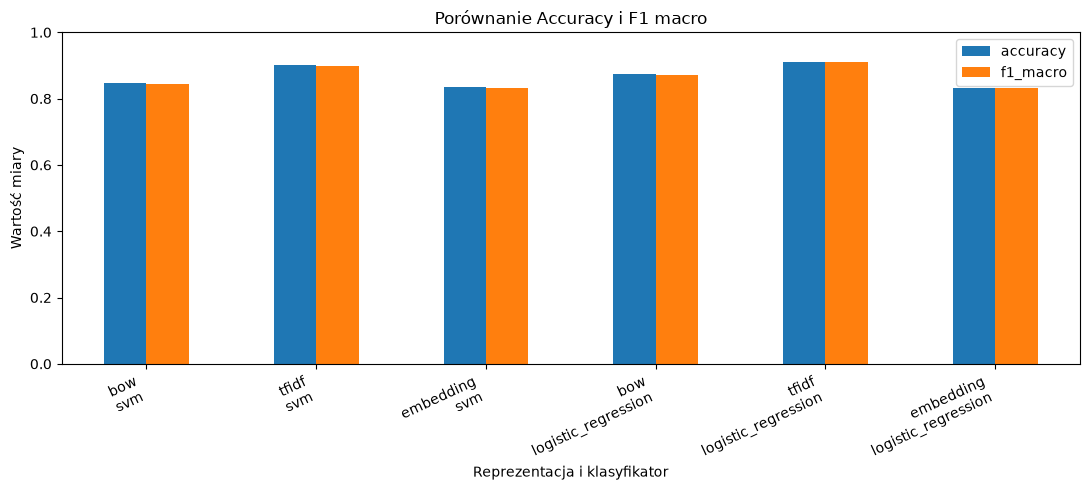

In [12]:
plot_data = summary_csv.copy()
plot_data["konfiguracja"] = plot_data["representation"] + "\n" + plot_data["classifier"]
ax = plot_data.plot(x="konfiguracja", y=["accuracy", "f1_macro"], kind="bar", figsize=(11, 5))
ax.set_ylabel("Wartość miary")
ax.set_xlabel("Reprezentacja i klasyfikator")
ax.set_ylim(0, 1)
ax.set_title("Porównanie Accuracy i F1 macro")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

### 6.2 Wyniki dla poszczególnych klas

Poniższa tabela zawiera precision, recall i F1 dla każdej kategorii w sześciu konfiguracjach.

In [13]:
per_class = pd.read_csv("results/per_class_metrics.csv")
display(per_class[["representation", "classifier", "class", "precision", "recall", "f1", "support"]]
        .sort_values(["class", "f1"], ascending=[True, False])
        .style.format({"precision": "{:.4f}", "recall": "{:.4f}", "f1": "{:.4f}"}))

,representation,classifier,class,precision,recall,f1,support
16,tfidf,logistic_regression,comp.graphics,0.9412,0.9215,0.9312,191
4,tfidf,svm,comp.graphics,0.9305,0.9110,0.9206,191
12,bow,logistic_regression,comp.graphics,0.9194,0.8953,0.9072,191
0,bow,svm,comp.graphics,0.8978,0.8743,0.8859,191
8,embedding,svm,comp.graphics,0.8883,0.8743,0.8813,191
20,embedding,logistic_regression,comp.graphics,0.8660,0.8796,0.8727,191
17,tfidf,logistic_regression,rec.sport.baseball,0.9365,0.9267,0.9316,191
5,tfidf,svm,rec.sport.baseball,0.9119,0.9215,0.9167,191
13,bow,logistic_regression,rec.sport.baseball,0.8349,0.9267,0.8784,191
1,bow,svm,rec.sport.baseball,0.8230,0.9005,0.8600,191


## 7. Macierze pomyłek

Macierz pomyłek przedstawia liczbę dokumentów przypisanych do poszczególnych klas. Wiersze oznaczają klasy rzeczywiste, a kolumny – klasy przewidziane przez model. Elementy na przekątnej odpowiadają poprawnym klasyfikacjom.

In [14]:
with open("results/confusion_matrices.json", encoding="utf-8") as f:
    matrices = json.load(f)
print("Dostępne konfiguracje:", list(matrices.keys()))

Dostępne konfiguracje: ['bow_svm', 'tfidf_svm', 'embedding_svm', 'bow_logistic_regression', 'tfidf_logistic_regression', 'embedding_logistic_regression']


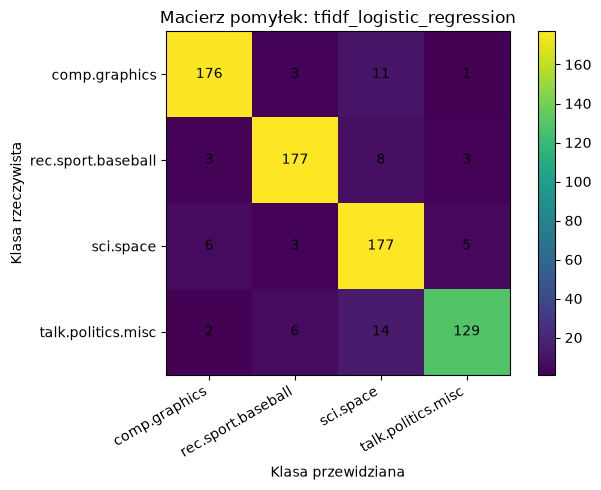

In [15]:
# Prezentacja macierzy pomyłek dla najlepszej konfiguracji według F1 macro.
best_row = summary_csv.sort_values("f1_macro", ascending=False).iloc[0]
best_name = f"{best_row['representation']}_{best_row['classifier']}"
best_result = matrices[best_name]
best_matrix = np.asarray(best_result["matrix"], dtype=int)
labels = best_result["labels"]

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(best_matrix)
ax.set_xticks(range(len(labels)), labels=labels, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), labels=labels)
ax.set_xlabel("Klasa przewidziana")
ax.set_ylabel("Klasa rzeczywista")
ax.set_title(f"Macierz pomyłek: {best_name}")
for i in range(best_matrix.shape[0]):
    for j in range(best_matrix.shape[1]):
        ax.text(j, i, best_matrix[i, j], ha="center", va="center")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## 8. Klasyfikacja własnych zdań

Dodatkowo przygotowano 16 zdań spoza zbioru testowego. Zdania dotyczą czterech analizowanych tematów. Każde zdanie sklasyfikowano wszystkimi sześcioma konfiguracjami, a przewidywania porównano z przypisaną wcześniej kategorią.

In [16]:
own = pd.read_csv("results/own_sentences_predictions.csv")
display(own.head(12))

,sentence,expected,representation,classifier,predicted,correct,probability
0,How do I render a 3D scene with realistic shadows using OpenGL?,comp.graphics,bow,svm,comp.graphics,1,NaN
1,"Which image format keeps more detail, JPEG or PNG, when I resize a picture?",comp.graphics,bow,svm,comp.graphics,1,NaN
2,My graphics card draws polygons very slowly in the new rendering software.,comp.graphics,bow,svm,comp.graphics,1,NaN
3,I need a program that converts bitmap images to vector graphics.,comp.graphics,bow,svm,comp.graphics,1,NaN
4,NASA plans to launch a new probe to study the moons of Jupiter.,sci.space,bow,svm,sci.space,1,NaN
5,The shuttle crew repaired the orbiting telescope during a spacewalk.,sci.space,bow,svm,sci.space,1,NaN
6,Astronomers detected a distant planet orbiting a nearby star.,sci.space,bow,svm,rec.sport.baseball,0,NaN
7,How much fuel does a rocket need to reach low earth orbit?,sci.space,bow,svm,sci.space,1,NaN
8,The pitcher struck out ten batters and the team won in the ninth inning.,rec.sport.baseball,bow,svm,rec.sport.baseball,1,NaN
9,Our shortstop hit a home run in the playoff game last night.,rec.sport.baseball,bow,svm,rec.sport.baseball,1,NaN


In [17]:
own_summary = (own.groupby(["representation", "classifier"])["correct"]
               .agg(["sum", "count", "mean"]).reset_index())
own_summary["accuracy_own"] = own_summary["mean"]
display(own_summary.drop(columns="mean").style.format({"accuracy_own": "{:.2%}"}))

,representation,classifier,sum,count,accuracy_own
0,bow,logistic_regression,16,16,100.00%
1,bow,svm,15,16,93.75%
2,embedding,logistic_regression,15,16,93.75%
3,embedding,svm,16,16,100.00%
4,tfidf,logistic_regression,15,16,93.75%
5,tfidf,svm,16,16,100.00%


## 9. Obsługa klasyfikacji w bocie Discord

Klasyfikacja została udostępniona przez komendę `/classifier`. Użytkownik podaje tekst, sposób czyszczenia, reprezentację oraz klasyfikator. Komenda wykorzystuje zapisany model, a jeśli model nie istnieje, może go wytrenować.

Komenda `/evaluate` prezentuje macierz pomyłek i metryki wybranej konfiguracji. Komenda `/prepare_data_for_classification` służy natomiast do ręcznego przypisywania etykiet `praca`, `dom` i `nauka` zadaniom TODO. Są to etykiety niezależne od klas zbioru 20 Newsgroups.

In [18]:
# Przykładowe wywołanie logiki klasyfikacji bez łączenia się z Discordem.
example_text = "NASA is developing a new spacecraft for space exploration."
example_result = clf.classify(
    example_text, method_repr="tfidf",
    method_class="svm", cleaning="clean"
)
display(example_result)

{'predicted': 'sci.space',
 'probability': None,
 'representation': 'tfidf',
 'classifier': 'svm',
 'cleaning': 'clean',
 'cleaned_text': 'nasa is developing new spacecraft for space exploration',
 'trained_now': False}

## 10. Podsumowanie wymagań

| Wymaganie | Realizacja |
|---|---|
| Trzy reprezentacje tekstu | BoW, TF-IDF, embeddingi spaCy |
| Dwa klasyfikatory | Linear SVM i Logistic Regression |
| Sześć konfiguracji | Wszystkie kombinacje trzech reprezentacji i dwóch klasyfikatorów |
| Podział danych | 80/20, stratify, `random_state=42` |
| Ewaluacja | ACC, ERR, precision, recall, F1, macierze pomyłek |
| Klasyfikacja własnych zdań | 16 zdań ocenionych przez sześć konfiguracji |
| Integracja z Discordem | `/classifier`, `/evaluate`, `/prepare_data_for_classification` |
| Oddzielne etykiety TODO | `praca`, `dom`, `nauka` – niezależne od 20 Newsgroups |

## 11. Wnioski

Najlepszy wynik uzyskano dla reprezentacji TF-IDF połączonej z regresją logistyczną. Konfiguracja ta osiągnęła Accuracy równe 0,9102 oraz F1 macro równe 0,9096. TF-IDF uzyskał wyższe wyniki niż BoW i embeddingi spaCy dla obu zastosowanych klasyfikatorów. W badanym zbiorze klasyfikatory oparte na częstości słów okazały się skuteczniejsze od reprezentacji wektorowej spaCy.

Regresja logistyczna uzyskała nieco lepsze wyniki niż Linear SVM dla BoW i TF-IDF. Dla embeddingów wyniki obu klasyfikatorów były zbliżone i niższe od pozostałych reprezentacji. Najwyższe F1 dla konfiguracji TF-IDF + Logistic Regression uzyskano dla kategorii `rec.sport.baseball` (0,9316) i `comp.graphics` (0,9312). Niższy wynik uzyskano dla `sci.space` (0,8828) oraz `talk.politics.misc` (0,8927).

Wyniki własnych zdań stanowią dodatkową kontrolę działania modeli, ale ze względu na niewielką liczbę przykładów nie zastępują oceny na zbiorze testowym. Wnioski dotyczą czterech wybranych kategorii anglojęzycznego zbioru 20 Newsgroups i nie powinny być bezpośrednio przenoszone na polskie zadania TODO.